<a href="https://colab.research.google.com/github/chaimaao0/ml-data-science-internship/blob/main/iris_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multi-Class Benchmark Classification Pipeline (Iris)



## 1. Import Libraries

In [34]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix)

RANDOM_STATE = 42

## 2. Load the Data
We load the Iris file with Pandas, check its shape and make sure there are no missing values.

In [37]:
# Load the Iris file
df = pd.read_csv("/content/sample_data/iris.csv")
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
df.head()

Shape: (150, 5)
Missing values: 0


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory Pairplot
Each species has its own color. We can see that *setosa* is clearly separated from the other two species, while *versicolor* and *virginica* overlap a little. Petal length and petal width separate the species best.

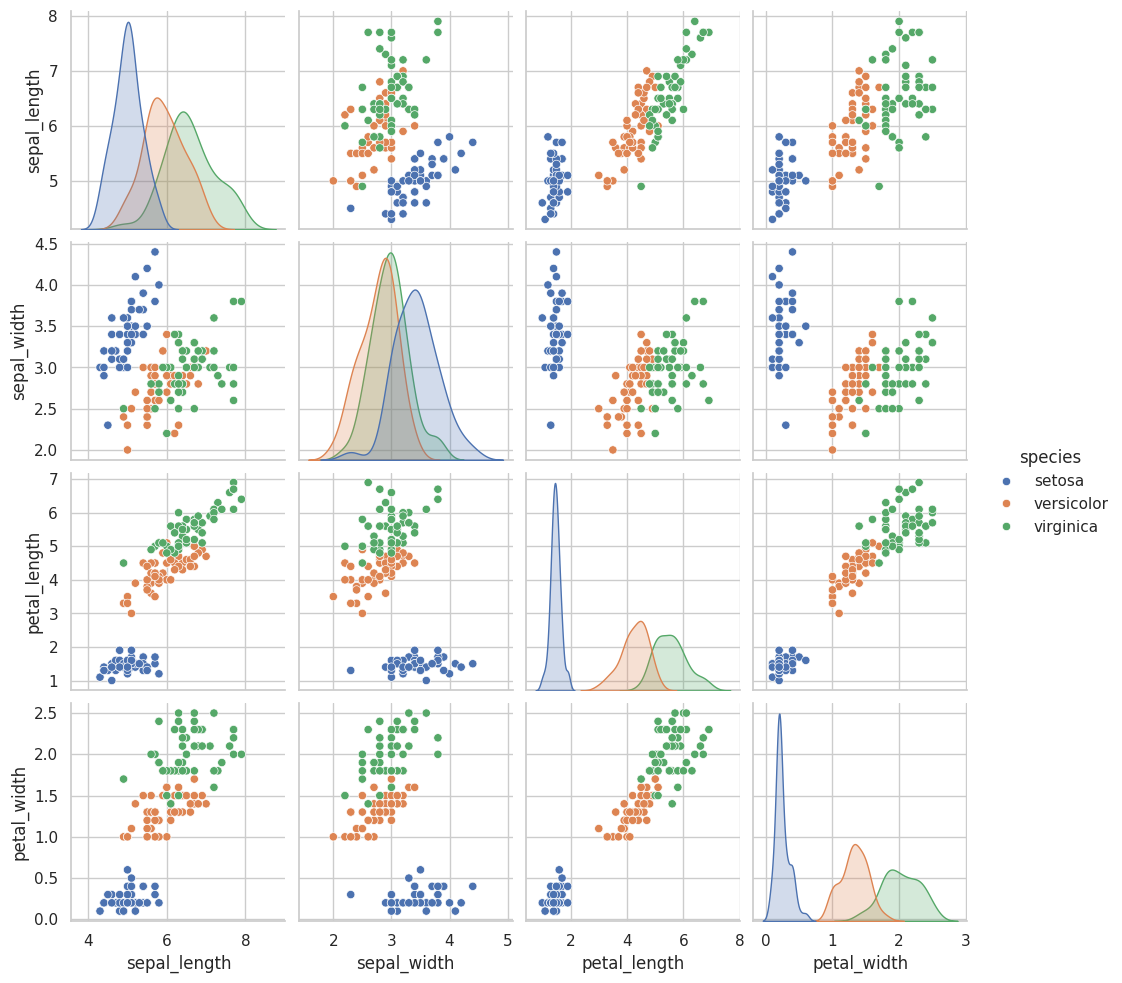

In [38]:
sns.pairplot(df, hue="species")
plt.show()

## 4. Split and Scale
We separate the features (X) from the target (y), encode the species as numbers (0, 1, 2), and split the data 80/20 using `random_state=42` and `stratify=y`.

The `StandardScaler` is fitted **only on the training data** and then used to transform the test data. This avoids data leakage.

In [39]:
X = df.drop(columns="species")
le = LabelEncoder()
y = le.fit_transform(df["species"])
class_names = list(le.classes_)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (120, 4) | Test: (30, 4)


## 5. Train the Models
- **Logistic Regression:** computes a score for each species from the features and predicts the most likely one. It draws straight boundaries. We train it on the scaled data.
- **Decision Tree:** asks a series of yes/no questions about the features. It draws rectangular boundaries and does not need scaling, so we train it on the original data.

Both models use the same training/testing split.

In [49]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train)


LogisticRegression(max_iter=1000)

In [50]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

## 6. Evaluation
We evaluate both models on the test set (30 flowers they have never seen). First, the detailed classification reports:

In [54]:
pred_log = log_reg.predict(X_test_scaled)
pred_tree = tree.predict(X_test)

print(" Logistic Regression ")
print(classification_report(y_test, pred_log, target_names=class_names))

print("Decision Tree")
print(classification_report(y_test, pred_tree, target_names=class_names))


 Logistic Regression 
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



Comparison table with accuracy, precision, recall and F1-score :

In [55]:
def metrics(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, average="weighted"),
            "Recall": recall_score(y_true, y_pred, average="weighted"),
            "F1-score": f1_score(y_true, y_pred, average="weighted")}

results = pd.DataFrame([metrics(y_test, pred_log), metrics(y_test, pred_tree)],
                       index=["Logistic Regression", "Decision Tree"]).round(4)
results

,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


## 7. Confusion Matrices
Rows are the **true** species and columns are the **predicted** species. The diagonal shows correct predictions; any number outside the diagonal is a mistake.

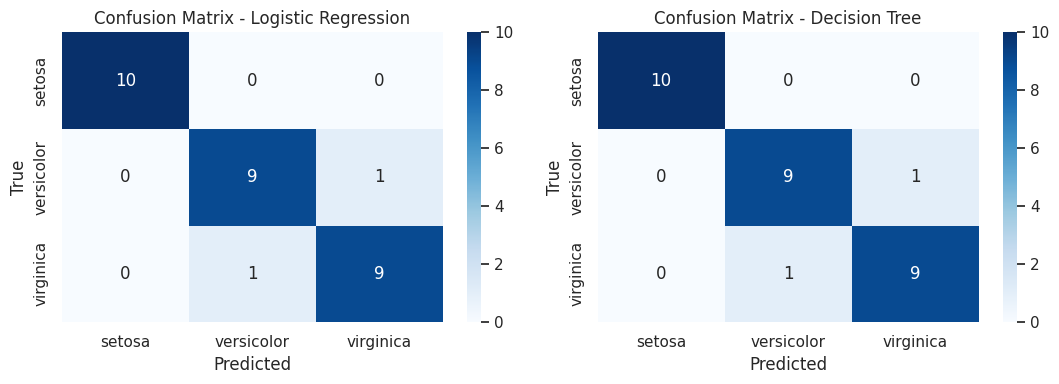

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, name in zip(axes, [pred_log, pred_tree], ["Logistic Regression", "Decision Tree"]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.show()

## 8. Decision Boundaries
Here we use **only 2 features** (petal length and petal width) so that we can draw them on a plot. We train **new models** just for this visualization (Logistic Regression with its own scaler). The main pipeline above uses all 4 features.

We create a mesh grid that covers the whole plot area, predict a species for every point of the grid, and color the regions.

In [57]:
cols = ["petal_length", "petal_width"]
X2_train = X_train[cols]

scaler2 = StandardScaler()
log2 = LogisticRegression(max_iter=1000).fit(scaler2.fit_transform(X2_train), y_train)
tree2 = DecisionTreeClassifier(random_state=42).fit(X2_train, y_train)

xx, yy = np.meshgrid(np.arange(0.5, 7.5, 0.02), np.arange(0, 3, 0.02))
grid = pd.DataFrame({"petal_length": xx.ravel(), "petal_width": yy.ravel()})

Z_log = log2.predict(scaler2.transform(grid)).reshape(xx.shape)
Z_tree = tree2.predict(grid).reshape(xx.shape)

Decision regions with the real data points. Logistic Regression draws straight lines and the Decision Tree draws rectangles.

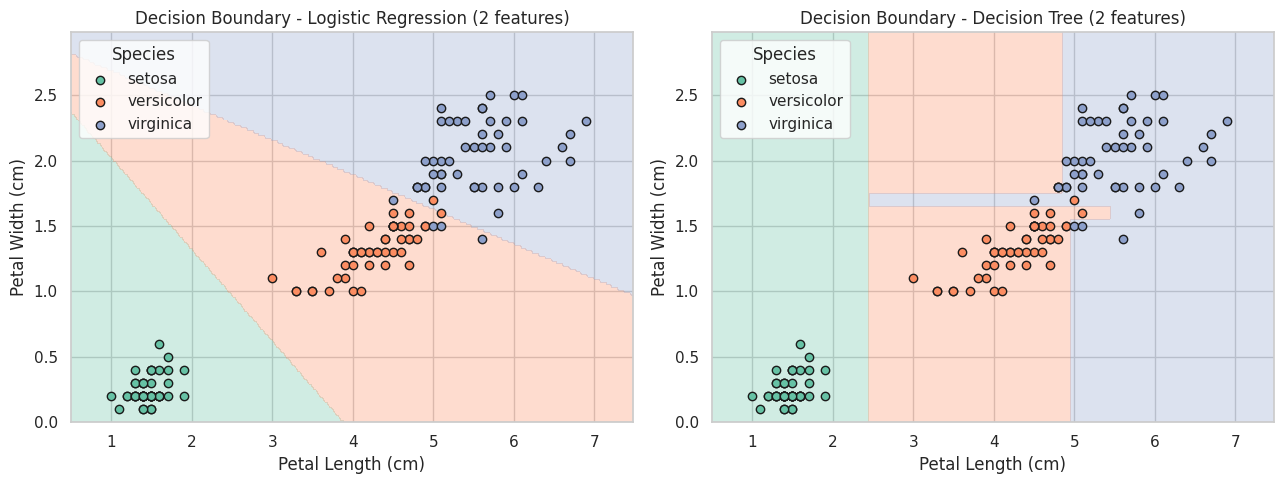

In [58]:
colors = ["#66c2a5", "#fc8d62", "#8da0cb"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, Z, name in zip(axes, [Z_log, Z_tree], ["Logistic Regression", "Decision Tree"]):
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5], colors=colors, alpha=0.3)
    for i, species in enumerate(class_names):
        d = df[df["species"] == species]
        ax.scatter(d["petal_length"], d["petal_width"], color=colors[i],
                   edgecolor="k", label=species)
    ax.set_title(f"Decision Boundary - {name} (2 features)")
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")
    ax.legend(title="Species")

plt.tight_layout()
plt.show()

## 9. Conclusion
Both models classify the three iris species well. On the test set, Logistic Regression and the Decision Tree obtained the same score (accuracy, precision, recall and F1 = 0.9333, which is 28 correct predictions out of 30), so neither model is better here.

The confusion matrices show that *setosa* was predicted perfectly, and that each model made 2 mistakes between *versicolor* and *virginica*, the two species that overlap in the pairplot. The test set is small (30 flowers), so the same two borderline flowers were misclassified by both models.

The boundary plots show the difference between the algorithms: Logistic Regression uses smooth straight lines, while the Decision Tree uses rectangular regions and even creates a thin strip near the versicolor/virginica border, which is a sign that it fits individual points (a risk of overfitting).

Since Iris is a small and easy dataset, a tie does not mean the models are identical, only that they perform equally well on this test set. As a next step, cross-validation could be used for a more reliable comparison.